# Objectifs

**Contexte** : ville de Seattle, objectif neutralité carbone 2050. Les relevés de 2016 sont coûteux : on veut prédire les bâtiments pas encore mesurés.

**Périmètre** : bâtiments **non résidentiels** uniquement (les `Multifamily` sont exclus).

**Cibles à prédire** (2 modèles séparés) :
- `TotalGHGEmissions` : émissions de CO2
- `SiteEnergyUse(kBtu)` : consommation totale d'énergie

**Question clé** : est-ce que `ENERGYSTARScore` vaut le coup ? Comparer les performances **avec vs sans**.

**Les 5 étapes du brief** :
1. EDA en vérifiant les erreurs du jeu de données (en cours)
2. Réduction des dimensions
3. Tester plusieurs modèles de prédiction
4. Vérifier que les modèles ne sont pas mal entraînés (over/under-fitting)
5. Optimiser les hyperparamètres du modèle final retenu

# Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import seaborn as sns

# Etape 1 : Exploration

In [2]:
df = pd.read_csv("csv/2016-building-energy-benchmarking.csv")
df.head(3)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [4]:
df.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,...,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,...,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,...,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,...,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,...,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,...,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,...,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000


## Cibles à prédire

In [5]:
cibles = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']

### Valeurs manquates

In [6]:
missing = df[cibles].isna().sum().to_frame('nb_NaN')
missing['pct'] = (missing['nb_NaN'] / len(df) * 100).round(2)

print(missing)

                     nb_NaN   pct
TotalGHGEmissions         9  0.27
SiteEnergyUse(kBtu)       5  0.15


### Statistiques descriptives

In [36]:
print(df[cibles].describe().round(2))

       TotalGHGEmissions  SiteEnergyUse(kBtu)
count            3367.00         3.371000e+03
mean              119.72         5.403667e+06
std               538.83         2.161063e+07
min                -0.80         0.000000e+00
25%                 9.50         9.251286e+05
50%                33.92         1.803753e+06
75%                93.94         4.222455e+06
max             16870.98         8.739237e+08



--- Statistiques descriptives ---
       TotalGHGEmissions  SiteEnergyUse(kBtu)
count            3367.00         3.371000e+03
mean              119.72         5.403667e+06
std               538.83         2.161063e+07
min                -0.80         0.000000e+00
25%                 9.50         9.251286e+05
50%                33.92         1.803753e+06
75%                93.94         4.222455e+06
max             16870.98         8.739237e+08

Valeurs négatives :
TotalGHGEmissions      1
SiteEnergyUse(kBtu)    0
dtype: int64
Valeurs nulles :
TotalGHGEmissions       9
SiteEnergyUse(kBtu)    18
dtype: int64

Skew brut :
TotalGHGEmissions      19.48
SiteEnergyUse(kBtu)    24.84
dtype: float64
Skew après log1p :
TotalGHGEmissions      0.34
SiteEnergyUse(kBtu)   -3.86
dtype: float64

Corrélation entre les deux cibles : 0.863


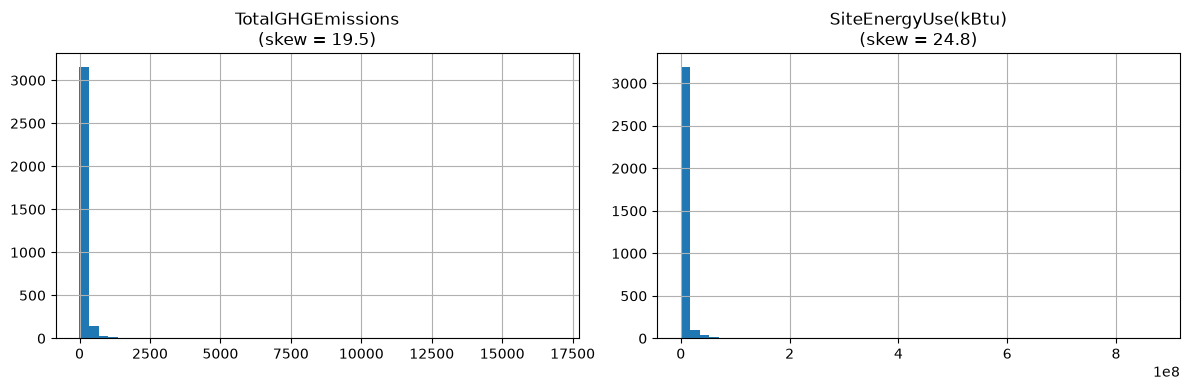

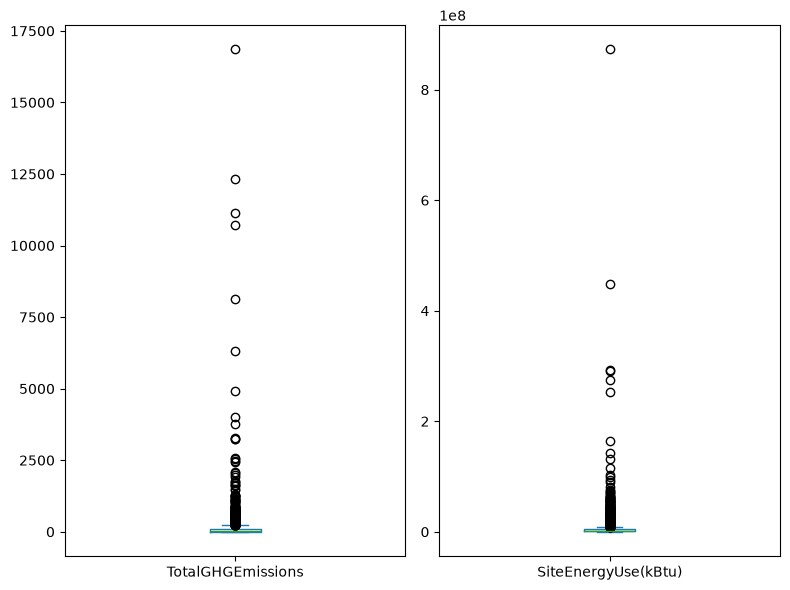

In [ ]:
# 3) Valeurs aberrantes évidentes
print('\nValeurs négatives :')
print((df[cibles] < 0).sum())
print('Valeurs nulles :')
print((df[cibles] == 0).sum())

# 4) Asymétrie (skew) : très > 0 -> envisager une transformation log
print('\nSkew brut :')
print(df[cibles].skew().round(2))
print('Skew après log1p :')
print(np.log1p(df[cibles].clip(lower=0)).skew().round(2))

# 5) Corrélation entre les deux cibles
print('\nCorrélation entre les deux cibles :',
      round(df[cibles].corr().iloc[0, 1], 3))

# 6) Distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, cibles):
    df[col].dropna().hist(bins=50, ax=ax)
    ax.set_title(f'{col}\n(skew = {df[col].skew():.1f})')
plt.tight_layout()
plt.show()

# 7) Boxplots -> visualisation des outliers
df[cibles].plot(kind='box', subplots=True, sharey=False, figsize=(8, 6))
plt.tight_layout()
plt.show()

### Conclusion de l'analyse des cibles

- **NaN** : 9 pour `TotalGHGEmissions`, 5 pour `SiteEnergyUse(kBtu)` → ces lignes sont retirées à l'étape 2.
- **Distribution très asymétrique** : skew de 19,5 et 24,8. Une transformation logarithmique sera à envisager avant modélisation.
- **Attention aux zéros** : 9 et 18 valeurs nulles. Le skew après `log1p` devient négatif pour `SiteEnergyUse` (-3,9) à cause de ces zéros : sur les seules valeurs strictement positives, le skew tombe à 0,7. À traiter au cas par cas.
- **Valeur suspecte** : 1 valeur négative sur `TotalGHGEmissions` (impossible physiquement).
- **Corrélation** : 0,86 entre les deux cibles → elles sont liées mais restent deux prédictions distinctes.

## Verification des doubles

In [8]:
df.duplicated().sum()

np.int64(0)

# Valeurs unique

In [9]:
df.nunique().sort_values().to_frame('nb_valeurs_uniques')

,nb_valeurs_uniques
Comments,0
DataYear,1
City,1
State,1
DefaultData,2
Outlier,2
ComplianceStatus,4
CouncilDistrictCode,7
BuildingType,8
NumberofBuildings,17


## Vérification des NaN

### Pourcentage de NaN

In [10]:
(df.isna().mean() * 100).loc[lambda s: s > 0].round(2).sort_values(ascending=False)

Comments                           100.00
Outlier                             99.05
YearsENERGYSTARCertified            96.48
ThirdLargestPropertyUseType         82.35
ThirdLargestPropertyUseTypeGFA      82.35
SecondLargestPropertyUseType        50.27
SecondLargestPropertyUseTypeGFA     50.27
ENERGYSTARScore                     24.97
LargestPropertyUseTypeGFA            0.59
LargestPropertyUseType               0.59
ZipCode                              0.47
ListOfAllPropertyUseTypes            0.27
NaturalGas(kBtu)                     0.27
SourceEUI(kBtu/sf)                   0.27
Electricity(kBtu)                    0.27
Electricity(kWh)                     0.27
SteamUse(kBtu)                       0.27
SourceEUIWN(kBtu/sf)                 0.27
TotalGHGEmissions                    0.27
NaturalGas(therms)                   0.27
GHGEmissionsIntensity                0.27
NumberofBuildings                    0.24
SiteEUI(kBtu/sf)                     0.21
SiteEUIWN(kBtu/sf)                

### Liste des colonnes avec des NaN

In [11]:
cols_nan = df.columns[df.isna().any()]
cols_nan

Index(['ZipCode', 'NumberofBuildings', 'ListOfAllPropertyUseTypes',
       'LargestPropertyUseType', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
       'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
       'YearsENERGYSTARCertified', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
       'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)',
       'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)',
       'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)',
       'NaturalGas(kBtu)', 'Comments', 'Outlier', 'TotalGHGEmissions',
       'GHGEmissionsIntensity'],
      dtype='str')

### heatmap co-occurence des valeurs manquantes

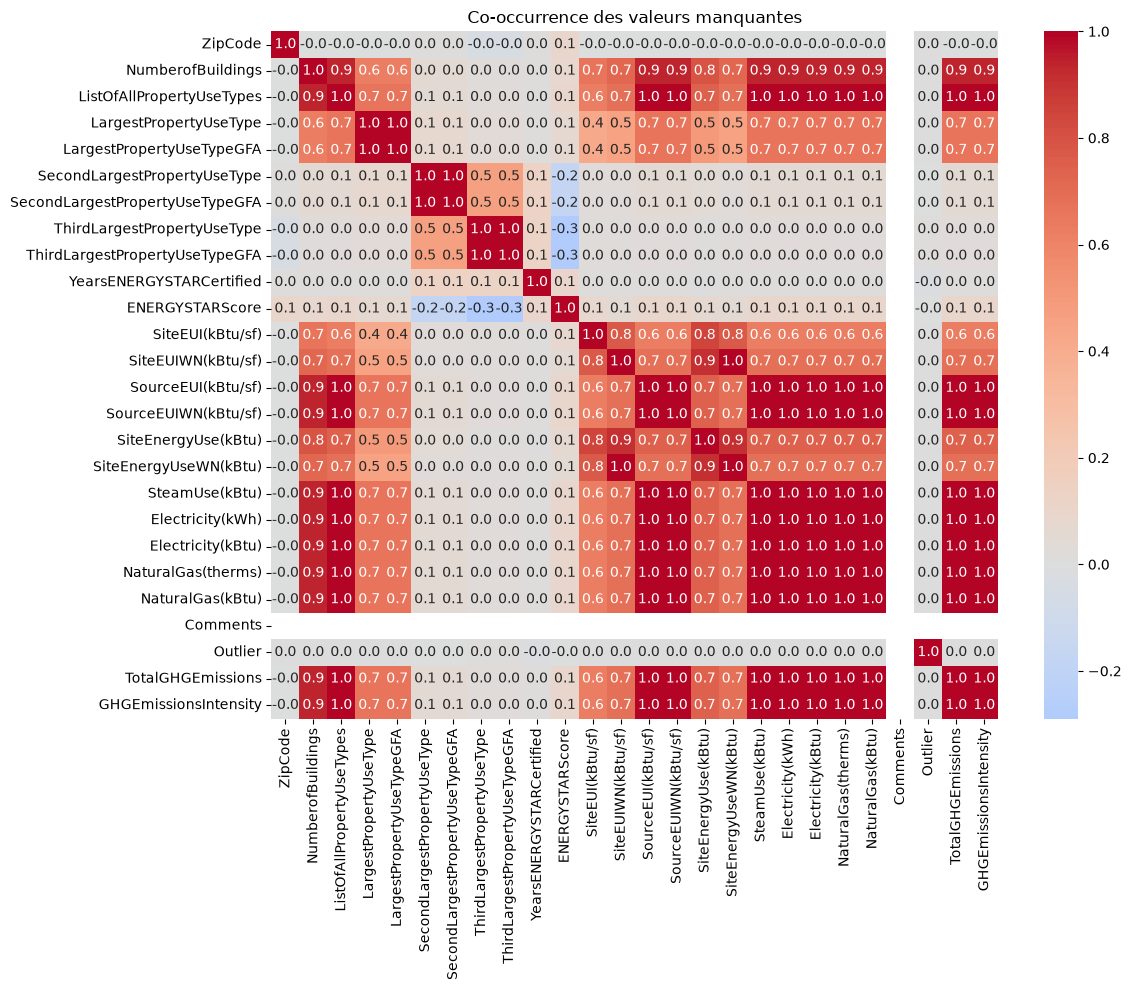

In [12]:
plt.figure(figsize=(12, 10))
sns.heatmap(df[cols_nan].isna().corr(),
            cmap='coolwarm', center=0,
            annot=True, fmt='.1f')
plt.title("Co-occurrence des valeurs manquantes")
plt.tight_layout()
plt.show()

In [13]:
df[df['TotalGHGEmissions'].isna()][['PropertyName', 'BuildingType', 'Outlier']]

,PropertyName,BuildingType,Outlier
578,SEATTLE BUILDING,NonResidential,NaN
758,SANDHURST APTS,Multifamily LR (1-4),NaN
1768,GRAHAM VIEW,Multifamily LR (1-4),NaN
1792,MERCER CREST APT,Multifamily LR (1-4),NaN
2321,PONDERAY APTS,Multifamily LR (1-4),NaN
2474,GRANVIEW APARTMENTS,Multifamily LR (1-4),NaN
2480,Villa Andora,Multifamily LR (1-4),NaN
2670,KALBERG BUILDING,NonResidential,NaN
3348,STREAM FIFTEEN,Multifamily LR (1-4),NaN


## Details

In [14]:
df["Comments"].info()

<class 'pandas.Series'>
RangeIndex: 3376 entries, 0 to 3375
Series name: Comments
Non-Null Count  Dtype  
--------------  -----  
0 non-null      float64
dtypes: float64(1)
memory usage: 26.5 KB


In [15]:
df['DataYear'].describe()

count    3376.0
mean     2016.0
std         0.0
min      2016.0
25%      2016.0
50%      2016.0
75%      2016.0
max      2016.0
Name: DataYear, dtype: float64

In [16]:
df["City"].describe()

count        3376
unique          1
top       Seattle
freq         3376
Name: City, dtype: object

In [17]:
df['BuildingType'].value_counts()

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

In [18]:
df['BuildingType'].value_counts().to_frame('nb').assign(
    pct=lambda t: (t['nb'] / len(df) * 100).round(2)
)

,nb,pct
BuildingType,,
NonResidential,1460,43.25
Multifamily LR (1-4),1018,30.15
Multifamily MR (5-9),580,17.18
Multifamily HR (10+),110,3.26
SPS-District K-12,98,2.90
Nonresidential COS,85,2.52
Campus,24,0.71
Nonresidential WA,1,0.03


### Cohérence des surfaces

In [ ]:
# La surface totale doit être égale à parking + bâtiment
surface_calculee = df['PropertyGFAParking'] + df['PropertyGFABuilding(s)']
ecart = (df['PropertyGFATotal'] - surface_calculee).abs()

print('Lignes avec un écart > 1 m² :', (ecart > 1).sum())
print('Écart maximum :', ecart.max())

df.loc[ecart > 1, ['PropertyName', 'PropertyGFATotal',
                   'PropertyGFAParking', 'PropertyGFABuilding(s)']].head(10)

### Bilan énergétique

In [ ]:
energie_somme = df[['SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)']].sum(axis=1)
ecart_energie = (energie_somme - df['SiteEnergyUse(kBtu)']).abs()
ecart_relatif = ecart_energie / df['SiteEnergyUse(kBtu)'].replace(0, np.nan)

print('Lignes avec plus de 1 % d écart :', (ecart_relatif > 0.01).sum())
print('Écart relatif max :', round(ecart_relatif.max(), 2))

df.loc[ecart_relatif > 0.01,
       ['PropertyName', 'BuildingType', 'SiteEnergyUse(kBtu)',
        'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)']].head(10)

### Lien entre ENERGY STAR et les cibles

In [ ]:
corr_es = df[['ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
              'GHGEmissionsIntensity', 'TotalGHGEmissions',
              'SiteEnergyUse(kBtu)']].corr().round(2)
print(corr_es)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, y in zip(axes, ['SiteEUI(kBtu/sf)', 'GHGEmissionsIntensity']):
    ax.scatter(df['ENERGYSTARScore'], df[y], alpha=0.3)
    ax.set_xlabel('ENERGYSTARScore')
    ax.set_ylabel(y)
plt.tight_layout()
plt.show()

### Corrélations features ↔ cibles

In [ ]:
num = df.select_dtypes(include=[np.number])
colonnes_cibles = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']
corr_cibles = num.corr()[colonnes_cibles].round(2)

print(corr_cibles.sort_values('TotalGHGEmissions', ascending=False).head(15))

plt.figure(figsize=(6, 14))
sns.heatmap(corr_cibles, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Corrélation avec les deux cibles')
plt.tight_layout()
plt.show()

# Etape 2 : Préparation des données

## Reduction

### Lignes

- BuildingType : Toutes les données des immeubles résidentiels.

In [19]:
types_residentiels = ['Multifamily LR (1-4)',
                      'Multifamily MR (5-9)',
                      'Multifamily HR (10+)']

df_clean = df[~df['BuildingType'].isin(types_residentiels)].copy()

In [20]:
print(df.shape, '->', df_clean.shape)
df_clean['BuildingType'].value_counts()

(3376, 46) -> (1668, 46)


BuildingType
NonResidential        1460
SPS-District K-12       98
Nonresidential COS      85
Campus                  24
Nonresidential WA        1
Name: count, dtype: int64

### Lignes exclues

In [21]:
motif = np.where(df['BuildingType'].isin(types_residentiels), 'résidentiel',
        np.where(df['TotalGHGEmissions'].isna(), 'cible manquante', ''))

df_exclus = df[motif != ''].copy()
df_exclus['motif_exclusion'] = motif[motif != '']

print(df_exclus.shape)
df_exclus.groupby('motif_exclusion').size()
df_exclus[['OSEBuildingID', 'PropertyName', 'BuildingType',
           'motif_exclusion']].head(15)

(1710, 47)


,OSEBuildingID,PropertyName,BuildingType,motif_exclusion
9,13,Lyon Building,Multifamily MR (5-9),résidentiel
165,265,YWCA Opportunity Place,Multifamily MR (5-9),résidentiel
173,280,Wintonia,Multifamily MR (5-9),résidentiel
188,296,Cooper School Artist's Lofts,Multifamily LR (1-4),résidentiel
189,297,LAKE CITY COURT,Multifamily MR (5-9),résidentiel
190,299,Othello Building,Multifamily LR (1-4),résidentiel
486,655,Tashiro_kaplan,Multifamily MR (5-9),résidentiel
503,684,Legacy Centre & Arbor Place Tower,Multifamily HR (10+),résidentiel
505,688,ID Village Square 2,Multifamily MR (5-9),résidentiel
508,691,(ID691) OLYMPIC TOWER CONDOMINIUM,Multifamily HR (10+),résidentiel


In [22]:
df_clean = df_clean.dropna(subset=['TotalGHGEmissions', 'SiteEnergyUse(kBtu)'])
print(df_clean.shape)

(1666, 46)


### Colonnes

- DataYear : Valeur unique (2016)
- Comments : 100 % de NaN (aucune information)
- City : Valeur unique (Seattle)
- OSEBuildingID : Identifiant (1666 valeurs uniques / 1666 lignes)
- PropertyName : Identifiant textuel (1662 valeurs uniques / 1666)
- Address : Identifiant textuel (1645 valeurs uniques / 1666), localisation déjà portée par Latitude, Longitude, ZipCode et Neighborhood
- State : Valeur unique (WA)
- TaxParcelIdentificationNumber : Identifiant (1585 valeurs uniques / 1666)
- ComplianceStatus : Post-hoc (décidé après le relevé)
- Outlier : Post-hoc (étiquette dérivée de la consommation d'énergie)

In [23]:
df_clean = df_clean.drop(columns=['DataYear'])

In [24]:
df_clean = df_clean.drop(columns=['Comments'])

In [25]:
df_clean = df_clean.drop(columns=['City'])

In [26]:
df_clean = df_clean.drop(columns=['OSEBuildingID'])

In [27]:
df_clean = df_clean.drop(columns=['PropertyName'])

In [28]:
df_clean = df_clean.drop(columns=['Address'])

In [29]:
df_clean = df_clean.drop(columns=['State'])

In [30]:
df_clean = df_clean.drop(columns=['TaxParcelIdentificationNumber'])

In [31]:
df_clean = df_clean.drop(columns=['ComplianceStatus'])

In [32]:
df_clean = df_clean.drop(columns=['Outlier'])

In [33]:
df_clean

,BuildingType,PrimaryPropertyType,ZipCode,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,TotalGHGEmissions,GHGEmissionsIntensity
0,NonResidential,Hotel,98101.0,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,...,7.226362e+06,7.456910e+06,2003882.00,1.156514e+06,3.946027e+06,12764.529300,1.276453e+06,False,249.98,2.83
1,NonResidential,Hotel,98101.0,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,...,8.387933e+06,8.664479e+06,0.00,9.504252e+05,3.242851e+06,51450.816410,5.145082e+06,False,295.86,2.86
2,NonResidential,Hotel,98101.0,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,...,7.258702e+07,7.393711e+07,21566554.00,1.451544e+07,4.952666e+07,14938.000000,1.493800e+06,False,2089.28,2.19
3,NonResidential,Hotel,98101.0,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,...,6.794584e+06,6.946800e+06,2214446.25,8.115253e+05,2.768924e+06,18112.130860,1.811213e+06,False,286.43,4.67
4,NonResidential,Hotel,98121.0,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,...,1.417261e+07,1.465650e+07,0.00,1.573449e+06,5.368607e+06,88039.984380,8.803998e+06,False,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,Nonresidential COS,Office,NaN,2,GREATER DUWAMISH,47.56722,-122.31154,1990,1.0,1,...,8.497457e+05,9.430032e+05,0.00,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,20.94,1.70
3372,Nonresidential COS,Other,NaN,2,DOWNTOWN,47.59625,-122.32283,2004,1.0,1,...,9.502762e+05,1.053706e+06,0.00,1.162210e+05,3.965461e+05,5537.299805,5.537300e+05,False,32.17,2.01
3373,Nonresidential COS,Other,NaN,7,MAGNOLIA / QUEEN ANNE,47.63644,-122.35784,1974,1.0,1,...,5.765898e+06,6.053764e+06,0.00,5.252517e+05,1.792159e+06,39737.390630,3.973739e+06,False,223.54,16.99
3374,Nonresidential COS,Mixed Use Property,NaN,1,GREATER DUWAMISH,47.52832,-122.32431,1989,1.0,1,...,7.194712e+05,7.828413e+05,0.00,1.022480e+05,3.488702e+05,3706.010010,3.706010e+05,False,22.11,1.57


## Encodage

## Feature engeenering

### Verification

In [34]:
(df_clean.isna().mean() * 100).loc[lambda s: s > 0].round(2).sort_values(ascending=False)

YearsENERGYSTARCertified           96.48
ThirdLargestPropertyUseType        82.35
ThirdLargestPropertyUseTypeGFA     82.35
SecondLargestPropertyUseType       50.27
SecondLargestPropertyUseTypeGFA    50.27
ENERGYSTARScore                    24.97
LargestPropertyUseTypeGFA           0.59
LargestPropertyUseType              0.59
ZipCode                             0.47
ListOfAllPropertyUseTypes           0.27
TotalGHGEmissions                   0.27
SourceEUI(kBtu/sf)                  0.27
SourceEUIWN(kBtu/sf)                0.27
Electricity(kBtu)                   0.27
Electricity(kWh)                    0.27
SteamUse(kBtu)                      0.27
GHGEmissionsIntensity               0.27
NaturalGas(kBtu)                    0.27
NaturalGas(therms)                  0.27
NumberofBuildings                   0.24
SiteEUI(kBtu/sf)                    0.21
SiteEUIWN(kBtu/sf)                  0.18
SiteEnergyUseWN(kBtu)               0.18
SiteEnergyUse(kBtu)                 0.15
dtype: float64

## Exportation

In [35]:
df_clean.to_csv("csv/train_clean.csv", index=False)

# Etape 3 : Modelisation

# Question ENERGY STAR

# Verification

# Optimisation